# Duka Electronics Board Report: H1 2026
**Analyst:** Stanley Wanyoike Ngugi


## Storyboard

**Audience:** the Duka Electronics board: non-technical, short of time, and reading the one-page report on their phones before next week's meeting.

**Decision they own:** where to focus the company's money and effort in the second half of 2026.

**Big Idea:** Duka's growth hinges on laptops: they bring in 58% of revenue and explain 94% of the April-to-June drop, so protecting laptop sales is the H2 priority.

**SCR**
- **Situation:** Duka earned KES 71.8M from 1,000 orders in H1 2026, with laptops (58% of revenue) and the Nairobi branch (36%) carrying the business.
- **Complication:** Revenue peaked at KES 13.5M in April and fell 19% to KES 10.9M in June, and laptops explain 94% of that drop.
- **Resolution:** In H2, protect laptop stock and promotion, keep Nairobi well served, and grow online sales, where orders are worth as much as in-store (KES 71.2k vs 70.8k) and already make up 32% of orders.

**Charts needed, in story order, with insight titles**
1. *Situation*, ranked bars by product: "Laptops generate 58% of revenue (KES 41.5M)"
2. *Situation*, ranked bars by branch: "Nairobi earns 36% of revenue, 1.9x second-placed Mombasa"
3. *Complication*, line over months: "Revenue peaked in April at KES 13.5M, then fell 19% by June"
4. *Complication*, two lines over months (laptops vs all other products): "Laptops explain 94% of the drop from April to June"
5. *Resolution*, bars of average order value by channel: "Online orders match in-store value (KES 71.2k vs 70.8k) and are 32% of orders"

**Why these chart types:** bars rank categories (product, branch, channel) and are easy to read on a phone; lines show change over time (the monthly trend and the laptop split). No pie charts, because the board needs to compare sizes, not estimate angles. Grey carries the context, and one highlight colour (redberry `#8E0000`) marks the point of each chart; green (`#0BA184`) marks the online channel, the H2 opportunity.

In [1]:
import os, textwrap
if not os.path.exists("generate_data.py"):
    !git clone https://github.com/SWNgugi/plp-da-a4-student-eda-and-board-report.git
    %cd plp-da-a4-student-eda-and-board-report

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("duka_sales.csv"):
    !python generate_data.py
os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

REDBERRY, ACCENT, GREY, DARK, LIGHT = "#8E0000", "#0BA184", "#B8B8B8", "#333333", "#E6E6E6"
SOURCE = "Source: Duka Electronics sales data, Jan-Jun 2026 (1,000 orders)"
MONTHS = ["January", "February", "March", "April", "May", "June"]

sales = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
sales["revenue"] = sales["quantity"] * sales["unit_price"]
sales["month"] = sales["order_date"].dt.month_name()
sales.head()

fatal: destination path 'plp-da-a4-student-eda-and-board-report' already exists and is not an empty directory.
/content/plp-da-a4-student-eda-and-board-report


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000,June
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000,February
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000,January
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500,April
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500,March


In [2]:
by_product = sales.groupby("product")["revenue"].sum().sort_values(ascending=False) / 1e6   # KES million
by_branch = sales.groupby("branch")["revenue"].sum().sort_values(ascending=False) / 1e6
monthly = sales.groupby("month")["revenue"].sum().reindex(MONTHS) / 1e6
monthly_split = (sales.assign(group=np.where(sales["product"] == "Laptop", "Laptops", "All other products"))
                 .pivot_table(index="month", columns="group", values="revenue", aggfunc="sum")
                 .reindex(MONTHS) / 1e6)
channel = sales.groupby("channel").agg(orders=("revenue", "size"), aov=("revenue", "mean"))
channel["aov_k"] = channel["aov"] / 1000
channel["order_share"] = channel["orders"] / channel["orders"].sum() * 100

total_rev = sales["revenue"].sum() / 1e6
top_product, top_rev = by_product.index[0], by_product.iloc[0]
product_share = top_rev / by_product.sum() * 100
b1, b2 = by_branch.index[0], by_branch.index[1]
branch_share = by_branch.iloc[0] / by_branch.sum() * 100
branch_ratio = by_branch.iloc[0] / by_branch.iloc[1]
peak_month, peak, last_month = monthly.idxmax(), monthly.max(), MONTHS[-1]
last = monthly.iloc[-1]
drop_pct = (peak - last) / peak * 100
laptop_drop = monthly_split.loc[peak_month, "Laptops"] - monthly_split.loc[last_month, "Laptops"]
laptop_share_of_drop = laptop_drop / (peak - last) * 100
online_k, instore_k = channel.loc["Online", "aov_k"], channel.loc["In-store", "aov_k"]
online_share = channel.loc["Online", "order_share"]

print(f"Total revenue KES {total_rev:.1f}M | {top_product} {product_share:.1f}% | {b1} {branch_share:.1f}% ({branch_ratio:.2f}x {b2})")
print(f"Peak {peak_month} KES {peak:.1f}M -> {last_month} KES {last:.1f}M ({drop_pct:.1f}% fall); laptops explain {laptop_share_of_drop:.1f}%")
print(f"Online AOV KES {online_k:.1f}k vs in-store {instore_k:.1f}k; online is {online_share:.1f}% of orders")

Total revenue KES 71.8M | Laptop 57.9% | Nairobi 36.4% (1.86x Mombasa)
Peak April KES 13.5M -> June KES 10.9M (19.3% fall); laptops explain 94.5%
Online AOV KES 71.2k vs in-store 70.8k; online is 32.0% of orders


## Chart functions
Each chart is a function that takes an `ax`, so the same code draws the standalone chart and the panel in the one-page report. Titles are f-strings built from the numbers above. Design rules applied everywhere: grey for context, one highlight colour, no top/right/bottom borders, direct value labels, units on every chart, a source line under every chart.

In [3]:
def wrap(text, width=60):
    return textwrap.fill(text, width)

def tidy(ax, keep_bottom=False):
    """Remove clutter: no top/right borders (and no bottom unless asked), light left line, no tick marks."""
    for side in ["top", "right"] + ([] if keep_bottom else ["bottom"]):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(LIGHT)
    ax.tick_params(colors=DARK, labelsize=11, length=0)

def add_source(ax, y=-0.20):
    ax.text(0, y, SOURCE, transform=ax.transAxes, fontsize=8, color="#777777", va="top")

def hbar(ax, series, title, value_fmt, unit_label, highlight=REDBERRY):
    """Sorted horizontal bars: all grey except the top bar, with direct value labels."""
    s = series.sort_values()
    colors = [GREY] * (len(s) - 1) + [highlight]
    ax.barh(s.index, s.values, color=colors, height=0.65)
    for y, v in enumerate(s.values):
        ax.text(v + s.max() * 0.015, y, value_fmt.format(v), va="center", fontsize=11, color=DARK)
    ax.set_xlim(0, s.max() * 1.22)
    ax.set_xticks([])
    ax.set_xlabel(unit_label, fontsize=10, color="#555555", loc="left")
    ax.set_title(wrap(title), loc="left", fontsize=13, fontweight="bold", color=DARK)
    tidy(ax)
    add_source(ax)

def plot_product(ax):
    hbar(ax, by_product, f"{top_product}s generate {product_share:.0f}% of revenue (KES {top_rev:.1f}M)",
         "KES {:.1f}M", "Revenue by product, KES million")

def plot_branch(ax):
    hbar(ax, by_branch, f"{b1} earns {branch_share:.0f}% of revenue, {branch_ratio:.1f}x second-placed {b2}",
         "KES {:.1f}M", "Revenue by branch, KES million")

def plot_trend(ax):
    x = np.arange(len(MONTHS))
    ax.plot(x, monthly.values, color=GREY, linewidth=2.5, marker="o", markersize=6)
    pk = MONTHS.index(peak_month)
    ax.plot(pk, peak, "o", color=REDBERRY, markersize=10)
    ax.plot(len(MONTHS) - 1, last, "o", color=REDBERRY, markersize=10)
    for i, v in enumerate(monthly.values):
        highlight = i in (pk, len(MONTHS) - 1)
        ax.text(i, v + 0.9, f"{v:.1f}", ha="center", fontsize=11,
                color=REDBERRY if highlight else DARK, fontweight="bold" if highlight else "normal")
    ax.set_xticks(x)
    ax.set_xticklabels([m[:3] for m in MONTHS])
    ax.set_ylim(0, 17)
    ax.set_yticks([0, 5, 10, 15])
    ax.set_ylabel("Revenue, KES million", fontsize=10, color="#555555")
    ax.yaxis.grid(True, color=LIGHT)
    ax.set_axisbelow(True)
    ax.set_title(wrap(f"Revenue peaked in {peak_month} at KES {peak:.1f}M, then fell {drop_pct:.0f}% by {last_month}"),
                 loc="left", fontsize=13, fontweight="bold", color=DARK)
    tidy(ax, keep_bottom=True)
    ax.spines["bottom"].set_color(LIGHT)
    add_source(ax, -0.16)

def plot_laptops(ax):
    x = np.arange(len(MONTHS))
    lap = monthly_split["Laptops"]
    other = monthly_split["All other products"]
    ax.plot(x, lap.values, color=REDBERRY, linewidth=3, marker="o", markersize=6)
    ax.plot(x, other.values, color=GREY, linewidth=2.5, marker="o", markersize=6)
    pk = MONTHS.index(peak_month)
    ax.text(pk, lap.iloc[pk] + 0.7, f"{lap.iloc[pk]:.1f}", ha="center", fontsize=11, color=REDBERRY, fontweight="bold")
    ax.text(5, lap.iloc[5] - 1.5, f"{lap.iloc[5]:.1f}", ha="center", fontsize=11, color=REDBERRY, fontweight="bold")
    ax.text(pk, other.iloc[pk] + 0.7, f"{other.iloc[pk]:.1f}", ha="center", fontsize=11, color="#666666")
    ax.text(5, other.iloc[5] + 0.7, f"{other.iloc[5]:.1f}", ha="center", fontsize=11, color="#666666")
    ax.text(0.0, lap.iloc[0] + 1.0, "Laptops", color=REDBERRY, fontsize=11, fontweight="bold", ha="left")
    ax.text(0.0, other.iloc[0] - 1.8, "All other products", color="#666666", fontsize=11, ha="left")
    ax.set_xticks(x)
    ax.set_xticklabels([m[:3] for m in MONTHS])
    ax.set_ylim(0, 10.5)
    ax.set_yticks([0, 5, 10])
    ax.set_ylabel("Revenue, KES million", fontsize=10, color="#555555")
    ax.yaxis.grid(True, color=LIGHT)
    ax.set_axisbelow(True)
    ax.set_title(wrap(f"Laptops explain {laptop_share_of_drop:.0f}% of the drop from {peak_month} to {last_month}"),
                 loc="left", fontsize=13, fontweight="bold", color=DARK)
    tidy(ax, keep_bottom=True)
    ax.spines["bottom"].set_color(LIGHT)
    add_source(ax, -0.16)

def plot_channel(ax):
    s = channel["aov_k"].sort_values()
    colors = [ACCENT if c == "Online" else GREY for c in s.index]
    ax.barh(s.index, s.values, color=colors, height=0.65)
    for y, ch in enumerate(s.index):
        ax.text(s[ch] + 1.2, y, f"KES {s[ch]:.1f}k  ({channel.loc[ch, 'order_share']:.0f}% of orders)",
                va="center", fontsize=11, color=DARK)
    ax.set_xlim(0, s.max() * 1.75)
    ax.set_xticks([])
    ax.set_xlabel("Average order value, KES thousand", fontsize=10, color="#555555", loc="left")
    ax.set_title(wrap(f"Online orders match in-store value (KES {online_k:.1f}k vs {instore_k:.1f}k) and are {online_share:.0f}% of orders"),
                 loc="left", fontsize=13, fontweight="bold", color=DARK)
    tidy(ax)
    add_source(ax)

## Chart makeover: before and after
**Before:** the default Matplotlib bar chart of revenue by product, with no styling. **After:** the same data redesigned with the principles from the storyboard. Both are saved to `figures/`.

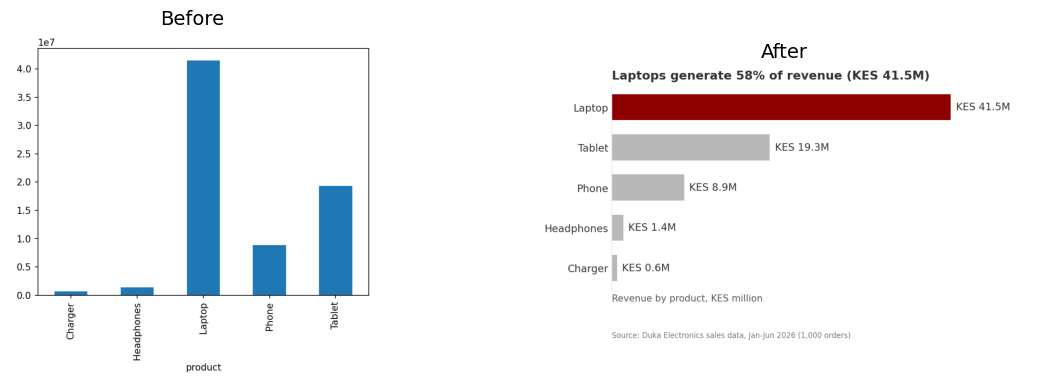

In [4]:
# BEFORE: default chart, no styling
fig, ax = plt.subplots()
sales.groupby("product")["revenue"].sum().plot(kind="bar", ax=ax)
fig.savefig("figures/before.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# AFTER: sorted, horizontal, decluttered, one highlight, direct labels, insight title
fig, ax = plt.subplots(figsize=(8, 4))
plot_product(ax)
fig.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# Side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for a, name in zip(axes, ["before", "after"]):
    a.imshow(plt.imread(f"figures/{name}.png"))
    a.set_title(name.capitalize(), fontsize=14)
    a.axis("off")
plt.show()

**What changed and why**

| Design change | Why it helps the board |
|---|---|
| Bars sorted from largest to smallest | The ranking is visible at a glance; the default alphabetical order hides it |
| Vertical bars became horizontal | Product and branch names are readable without rotating text, which matters on a phone |
| Top, right and bottom borders and the x-axis ticks removed | Less non-data ink, so the bars stand out |
| All bars grey except Laptop in redberry (#8E0000) | Colour is used for one purpose only: pointing at the message |
| Direct value labels ("KES 41.5M") instead of an axis | Readers get the number without tracing a gridline, and the unscientific "1e7" axis notation is gone |
| Generic default look replaced by an insight title computed in code ("Laptops generate 58% of revenue (KES 41.5M)") | The title states the takeaway and stays correct if the data changes |
| Units ("Revenue by product, KES million") and a source line added | The reader knows what is measured and where the numbers come from |

## The five charts
Each chart is shown on its own here, then combined into the one-page report below.

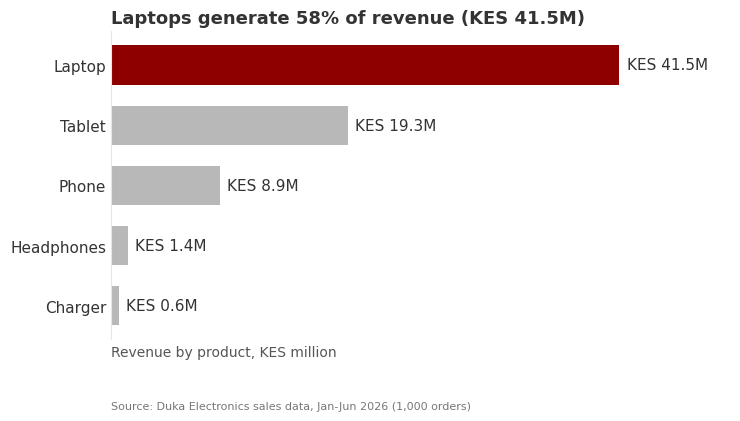

In [5]:
fig, ax = plt.subplots(figsize=(8, 4)); plot_product(ax); plt.show()

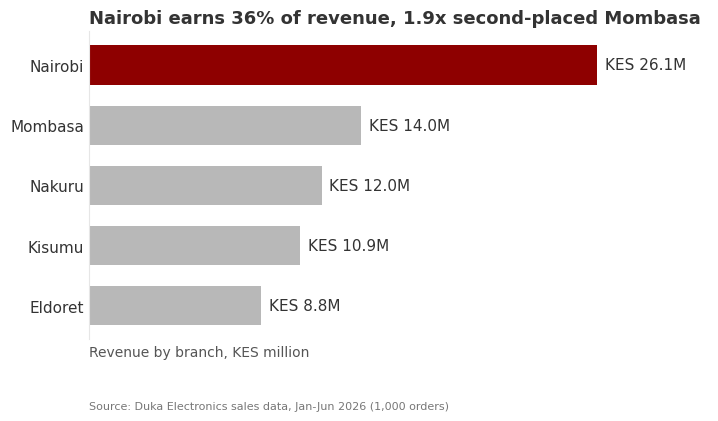

In [6]:
fig, ax = plt.subplots(figsize=(8, 4)); plot_branch(ax); plt.show()

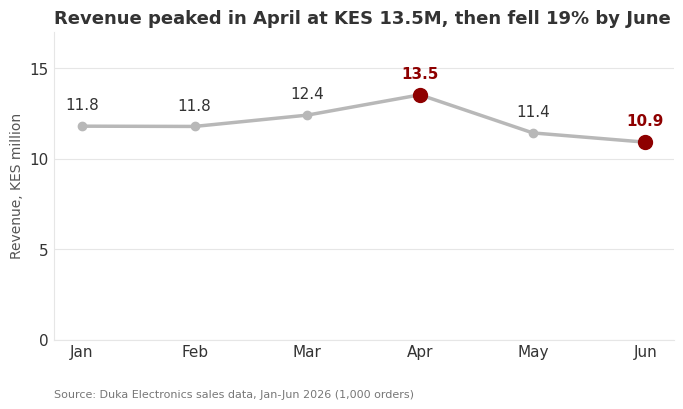

In [7]:
fig, ax = plt.subplots(figsize=(8, 4)); plot_trend(ax); plt.show()

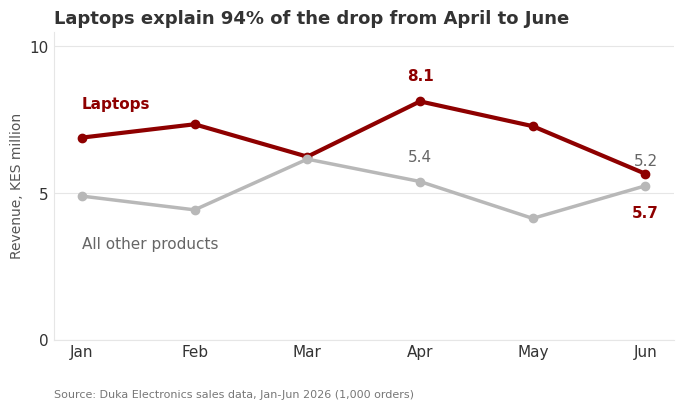

In [8]:
fig, ax = plt.subplots(figsize=(8, 4)); plot_laptops(ax); plt.show()

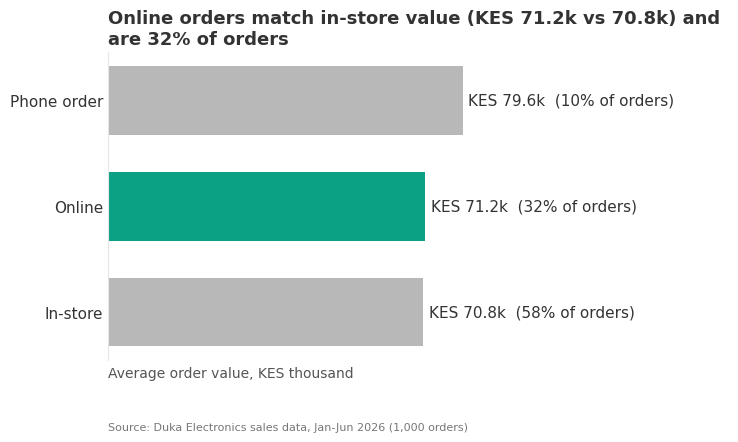

In [9]:
fig, ax = plt.subplots(figsize=(8, 4)); plot_channel(ax); plt.show()

## One-page board report
A tall, single-column page (8 × 20 inches) so it reads top to bottom on a phone. It follows the SCR story: Situation (charts 1 and 2), Complication (charts 3 and 4), Resolution (chart 5 and the recommendations). It is saved to `reports/duka_board_report.png`.

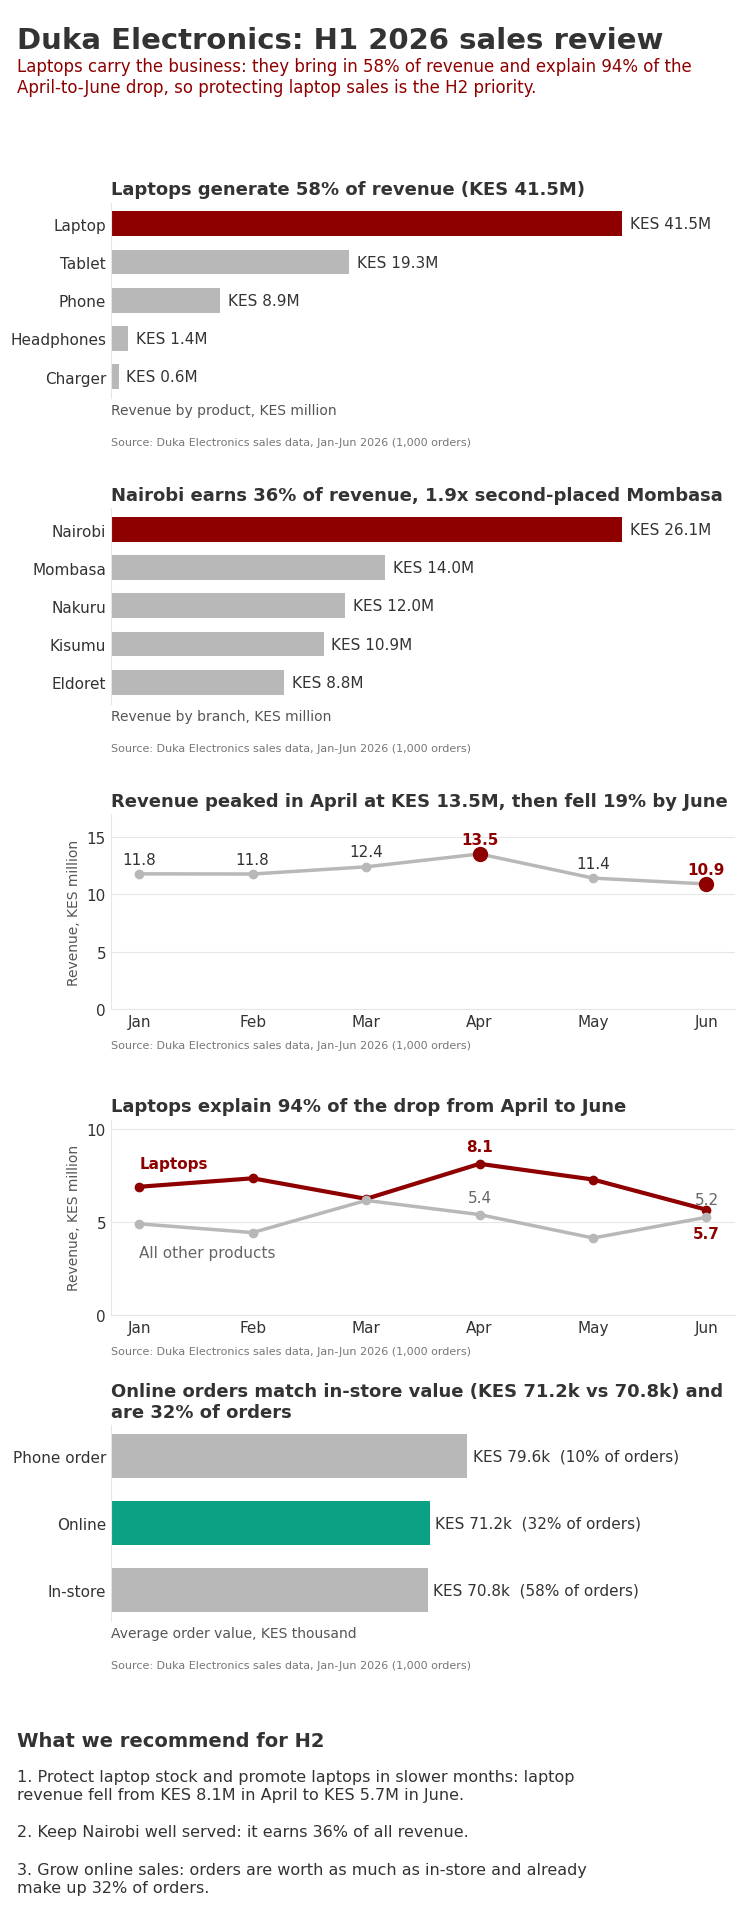

In [10]:
fig = plt.figure(figsize=(8, 20), facecolor="white")
gs = fig.add_gridspec(7, 1, height_ratios=[1.15, 2.7, 2.7, 2.7, 2.7, 2.7, 2.6], hspace=0.62,
                      left=0.17, right=0.95, top=0.985, bottom=0.03)

hdr = fig.add_subplot(gs[0]); hdr.axis("off")
hdr.text(-0.15, 0.80, "Duka Electronics: H1 2026 sales review", fontsize=21, fontweight="bold",
         color=DARK, va="top", transform=hdr.transAxes)
hdr.text(-0.15, 0.42, wrap(f"Laptops carry the business: they bring in {product_share:.0f}% of revenue and explain "
                           f"{laptop_share_of_drop:.0f}% of the April-to-June drop, so protecting laptop sales is the H2 priority.", 80),
         fontsize=12, color=REDBERRY, va="top", transform=hdr.transAxes)

for i, chart in enumerate([plot_product, plot_branch, plot_trend, plot_laptops, plot_channel], start=1):
    chart(fig.add_subplot(gs[i]))

rec = fig.add_subplot(gs[6]); rec.axis("off")
rec.text(-0.15, 1.0, "What we recommend for H2", fontsize=14, fontweight="bold", color=DARK,
         va="top", transform=rec.transAxes)
rec.text(-0.15, 0.80, "\n\n".join([
    wrap(f"1. Protect laptop stock and promote laptops in slower months: laptop revenue fell from "
         f"KES {monthly_split.loc[peak_month, 'Laptops']:.1f}M in {peak_month} to KES {monthly_split.loc[last_month, 'Laptops']:.1f}M in {last_month}.", 74),
    wrap(f"2. Keep {b1} well served: it earns {branch_share:.0f}% of all revenue.", 74),
    wrap(f"3. Grow online sales: orders are worth as much as in-store and already make up {online_share:.0f}% of orders.", 74)]),
    fontsize=11.5, color=DARK, va="top", transform=rec.transAxes, linespacing=1.3)

fig.savefig("reports/duka_board_report.png", dpi=200)
plt.show()

## Board Summary
Duka Electronics earned KES 71.8 million from 1,000 orders in the first half of 2026. Two things carry the business: laptops bring in 58% of revenue, and the Nairobi branch earns 36%, almost twice as much as Mombasa in second place. Revenue peaked in April at KES 13.5 million, then fell 19% to KES 10.9 million in June. Laptops explain 94% of that drop: laptop revenue went from KES 8.1 million to KES 5.7 million, while all other products together barely changed (KES 5.4 million to KES 5.2 million). Online orders are worth as much as in-store orders, about KES 71,000 each, and already make up 32% of orders. Our advice is simple: protect what works. We recommend three priorities for the second half. First, protect laptop stock and promote laptops in slower months. Second, keep Nairobi well served. Third, grow online sales, which carry no penalty on order value.

In [11]:
board_summary = """Duka Electronics earned KES 71.8 million from 1,000 orders in the first half of 2026. Two things carry the business: laptops bring in 58% of revenue, and the Nairobi branch earns 36%, almost twice as much as Mombasa in second place. Revenue peaked in April at KES 13.5 million, then fell 19% to KES 10.9 million in June. Laptops explain 94% of that drop: laptop revenue went from KES 8.1 million to KES 5.7 million, while all other products together barely changed (KES 5.4 million to KES 5.2 million). Online orders are worth as much as in-store orders, about KES 71,000 each, and already make up 32% of orders. Our advice is simple: protect what works. We recommend three priorities for the second half. First, protect laptop stock and promote laptops in slower months. Second, keep Nairobi well served. Third, grow online sales, which carry no penalty on order value."""
print("Board Summary word count:", len(board_summary.split()))

Board Summary word count: 150


## Story check
Every number used in the storyboard, report and Board Summary is recomputed from the data; each line should print OK.

In [12]:
lap, other = monthly_split["Laptops"], monthly_split["All other products"]
checks = [
 ("H1 revenue is KES 71.8M from 1,000 orders", round(total_rev, 1) == 71.8 and len(sales) == 1000),
 ("Laptops generate 58% of revenue (KES 41.5M)", top_product == "Laptop" and round(product_share) == 58 and round(top_rev, 1) == 41.5),
 ("Nairobi earns 36% of revenue, 1.9x Mombasa", b1 == "Nairobi" and b2 == "Mombasa" and round(branch_share) == 36 and round(branch_ratio, 1) == 1.9),
 ("Revenue peaked in April at KES 13.5M and fell 19% to KES 10.9M in June", peak_month == "April" and round(peak, 1) == 13.5 and round(last, 1) == 10.9 and round(drop_pct) == 19),
 ("Laptops explain 94% of the April-to-June drop", round(laptop_share_of_drop) == 94),
 ("Laptop revenue KES 8.1M to 5.7M; other products KES 5.4M to 5.2M", round(lap["April"], 1) == 8.1 and round(lap["June"], 1) == 5.7 and round(other["April"], 1) == 5.4 and round(other["June"], 1) == 5.2),
 ("Online AOV KES 71.2k vs in-store 70.8k; online is 32% of orders", round(online_k, 1) == 71.2 and round(instore_k, 1) == 70.8 and round(online_share) == 32),
 ("Board Summary is 150 words", len(board_summary.split()) == 150),
]
for text, ok in checks:
    print("OK      " if ok else "MISMATCH", text)
print("Files:", sorted(os.listdir("figures")), os.listdir("reports"))

OK       H1 revenue is KES 71.8M from 1,000 orders
OK       Laptops generate 58% of revenue (KES 41.5M)
OK       Nairobi earns 36% of revenue, 1.9x Mombasa
OK       Revenue peaked in April at KES 13.5M and fell 19% to KES 10.9M in June
OK       Laptops explain 94% of the April-to-June drop
OK       Laptop revenue KES 8.1M to 5.7M; other products KES 5.4M to 5.2M
OK       Online AOV KES 71.2k vs in-store 70.8k; online is 32% of orders
OK       Board Summary is 150 words
Files: ['after.png', 'bar_at_risk_by_county.png', 'before.png', 'box_score_by_school_type.png', 'corr_heatmap.png', 'hist_study_hours.png', 'scatter_trend_study_hours.png'] ['duka_board_report.png']
